# APRAU 2026/27 - Grupo 08
## Parte 1: Análise Exploratória de Dados (EDA)

**Objetivo geral do trabalho:** aplicar diferentes métodos de *machine learning* a um dataset clínico multidoença, analisar o comportamento dos modelos e interpretar criticamente os resultados.

**Objetivo deste notebook (secção 2 do enunciado):** caracterizar o dataset antes de modelar, identificando propriedades relevantes dos dados e relações entre variáveis. O dataset do grupo tem 2000 registos de pacientes, com duas variáveis-alvo:

- `target_class`: diagnóstico (3 classes: `N`, `HY`, `DI`), usada na classificação;
- `target_regression`: biomarcador laboratorial contínuo, usado na regressão.

**Estrutura (segue os pontos pedidos no enunciado):**

| Secção | Conteúdo | Ponto do enunciado |
|---|---|---|
| 1 | Visão geral do dataset | Dataset assignment |
| 2 | Estatística descritiva | *Descriptive Statistics* |
| 3 | Análise univariada | *Univariate Analysis* |
| 4 | Análise bivariada | *Bivariate Analysis* |
| 5 | Features constantes, redundantes e não informativas | Identificar e justificar |
| 6 | Conclusões | |
| Apêndice | Codificação das variáveis categóricas (preparação para modelação) | |

### Importações e carregamento dos dados

In [1]:
import pandas as pd
from tabulate import tabulate
import math
import re
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.linear_model import LinearRegression


In [2]:
df = pd.read_csv('dataset_grupo_08.csv')

---
## 1. Visão geral do dataset

Primeiro contacto com os dados: primeiras e últimas linhas, dimensão, duplicados, valores em falta, tipos de variáveis e cardinalidade. A cardinalidade (nº de valores distintos) ajuda a distinguir variáveis categóricas, discretas e contínuas, e a detetar variáveis constantes ou do tipo identificador.

### 1.1 Primeiras e últimas observações

In [3]:
print(
    f"""
    Head Dataset

    {tabulate(
        df.head(10),
        headers="keys",
        tablefmt="grid",
        showindex=False
    )}
    """
)

print(f"""
Tail Dataset

{tabulate(
    df.tail(10),
    headers="keys",
    tablefmt="grid",
    showindex=False
)}
""")


    Head Dataset

    +-------------+----------+-------------+-----------+-------+------------------+-------+---------------+---------------+---------------+-----------------+---------------------+------------------+----------------+-----------------------+------------------------+------------------+---------------------+-------------+----------------------+---------------+----------------+------------------+---------------+--------------+---------+---------+-------------------+---------------------+------------------+--------------------+----------------+-------------------+---------------------+----------------+
| age_level   | gender   | bmi_level   | smoking   |   age |   age_normalized |   bmi |   HbA1c_level |   cholesterol |   sleep_hours |   triglycerides | physical_activity   | family_history   | stress_level   | low_hdl_cholesterol   | high_ldl_cholesterol   |   blood_pressure | sugar_consumption   |   crp_level |   homocysteine_level |   systolic_bp |   diastolic_bp |   alc

### 1.2 Dimensão, duplicados e valores em falta

In [4]:
# ============================================================
# 1. DATA OVERVIEW
# ============================================================

print("=" * 60)
print("DATASET OVERVIEW")
print("=" * 60)

print(f"Number of observations: {df.shape[0]}")
print(f"Number of features: {df.shape[1]}")
print("Duplicated rows: " + str(df.duplicated().sum()))
print("\nData types and missing values:")
print(df.info())

DATASET OVERVIEW
Number of observations: 2000
Number of features: 35
Duplicated rows: 0

Data types and missing values:
<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 35 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   age_level             2000 non-null   str    
 1   gender                2000 non-null   str    
 2   bmi_level             2000 non-null   str    
 3   smoking               2000 non-null   str    
 4   age                   2000 non-null   int64  
 5   age_normalized        2000 non-null   float64
 6   bmi                   2000 non-null   float64
 7   HbA1c_level           2000 non-null   float64
 8   cholesterol           2000 non-null   float64
 9   sleep_hours           2000 non-null   float64
 10  triglycerides         2000 non-null   float64
 11  physical_activity     2000 non-null   str    
 12  family_history        2000 non-null   str    
 13  stress_level  

**Leitura:** 2000 observações e 35 colunas (33 features e os 2 alvos), sem linhas duplicadas e sem valores em falta, pelo que não é necessário tratar *missing values* nem remover duplicados.

### 1.3 Tipos de variáveis

In [5]:
# ============================================================
# 2. VARIABLE TYPES
# ============================================================

numeric_cols = df.select_dtypes(include="number").columns
categorical_cols = df.select_dtypes(include="object").columns

print("\n" + "=" * 60)
print("VARIABLE TYPES")
print("=" * 60)

print("\nNumerical variables:")
print(list(numeric_cols))

print("\nCategorical variables:")
print(list(categorical_cols))



VARIABLE TYPES

Numerical variables:
['age', 'age_normalized', 'bmi', 'HbA1c_level', 'cholesterol', 'sleep_hours', 'triglycerides', 'blood_pressure', 'crp_level', 'homocysteine_level', 'systolic_bp', 'diastolic_bp', 'alcohol_intake', 'salt_intake', 'heart_rate', 'hdl', 'ldl', 'systolic_index', 'calcium_baseline', 'plasma_value', 'ldl_alternative', 'target_regression']

Categorical variables:
['age_level', 'gender', 'bmi_level', 'smoking', 'physical_activity', 'family_history', 'stress_level', 'low_hdl_cholesterol', 'high_ldl_cholesterol', 'sugar_consumption', 'education_level', 'employment_status', 'target_class']


C:\Users\moale\AppData\Local\Temp\ipykernel_1752\2444264265.py:6: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df.select_dtypes(include="object").columns


**Leitura:** 21 features numéricas (mais `target_regression`) e 12 features categóricas (mais `target_class`). As categóricas ordinais (`bmi_level`, `physical_activity`, `stress_level`, `sugar_consumption`, `age_level`, ...) têm uma ordem natural, que é respeitada nos gráficos seguintes.

### 1.4 Cardinalidade

In [6]:
# ============================================================
# 3. CARDINALITY
# ============================================================

print("\n" + "=" * 60)
print("CARDINALITY")
print("=" * 60)

cardinality = pd.DataFrame({
    "Unique Values": df.nunique(),
    "Unique Percentage": df.nunique() / len(df) * 100,
    "type": list(df.dtypes)
})

display(cardinality.sort_values("Unique Values"))


CARDINALITY


,Unique Values,Unique Percentage,type
calcium_baseline,1,0.05,float64
gender,2,0.10,str
high_ldl_cholesterol,2,0.10,str
family_history,2,0.10,str
low_hdl_cholesterol,2,0.10,str
physical_activity,3,0.15,str
stress_level,3,0.15,str
smoking,3,0.15,str
employment_status,3,0.15,str
education_level,3,0.15,str


**Leitura:**
- `calcium_baseline` tem **um único valor** em todo o dataset (constante).
- `plasma_value` tem 100% de valores únicos, mas é uma medição contínua (0,68 a 1,75) e não um identificador.
- `systolic_bp`/`systolic_index` (213 valores), `age`/`age_normalized` e `ldl`/`ldl_alternative` (242 valores) têm cardinalidades iguais ou muito próximas, o que levanta suspeita de redundância (analisada na secção 5).

---
## 2. Estatística descritiva

Medidas de tendência central, dispersão e forma (assimetria e curtose) para as variáveis numéricas, e frequências para as categóricas. Inclui a caracterização das duas variáveis-alvo.

### 2.1 Variáveis numéricas

In [7]:
# ============================================================
# 4. DESCRIPTIVE STATISTICS - NUMERICAL VARIABLES
# ============================================================

print("\n" + "=" * 60)
print("DESCRIPTIVE STATISTICS - NUMERICAL VARIABLES")
print("=" * 60)

numeric_stats = pd.DataFrame({
    "Mean": df[numeric_cols].mean(),
    "Median": df[numeric_cols].median(),
    "Std": df[numeric_cols].std(),
    "Min": df[numeric_cols].min(),
    "Q1": df[numeric_cols].quantile(0.25),
    "Q3": df[numeric_cols].quantile(0.75),
    "Max": df[numeric_cols].max(),
    "IQR": (
        df[numeric_cols].quantile(0.75)
        - df[numeric_cols].quantile(0.25)
    ),
    "Skewness": df[numeric_cols].skew(),
    "Kurtosis": df[numeric_cols].kurtosis()
})

display(numeric_stats.round(3))



DESCRIPTIVE STATISTICS - NUMERICAL VARIABLES


,Mean,Median,Std,Min,Q1,Q3,Max,IQR,Skewness,Kurtosis
age,48.262,48.000,21.902,2.000,31.000,66.000,89.000,35.000,-0.021,-0.950
age_normalized,0.532,0.529,0.252,0.000,0.333,0.736,1.000,0.402,-0.021,-0.950
bmi,27.458,27.320,7.172,12.370,21.900,32.515,87.700,10.615,0.671,2.621
HbA1c_level,5.644,5.420,0.893,3.500,5.349,6.200,9.000,0.851,0.123,1.105
cholesterol,223.165,224.685,33.120,150.000,206.000,232.000,299.000,26.000,0.067,0.037
sleep_hours,6.923,6.966,1.351,4.000,6.485,7.300,10.000,0.815,0.035,0.042
triglycerides,182.474,183.000,66.656,50.000,137.000,243.640,399.000,106.640,-0.186,-0.873
blood_pressure,149.659,149.588,3.427,120.000,148.625,150.605,177.000,1.980,-0.522,24.144
crp_level,7.516,7.414,0.913,0.058,7.295,7.759,14.995,0.464,0.159,26.895
homocysteine_level,12.520,12.509,0.936,5.097,12.305,12.691,19.946,0.386,1.467,26.610


**Leitura:**
- `age_normalized` é a idade em escala 0-1 e `systolic_index` tem exatamente as mesmas estatísticas de `systolic_bp`.
- `ldl` e `ldl_alternative` têm também estatísticas idênticas.
- `blood_pressure`, `crp_level` e `homocysteine_level` têm curtose entre 24 e 27 e um IQR muito pequeno, ou seja, valores muito concentrados em torno da mediana com algumas caudas extremas.
- `calcium_baseline` tem desvio-padrão 0.

### 2.2 Variáveis categóricas

In [8]:
# ============================================================
# 5. DESCRIPTIVE STATISTICS - CATEGORICAL VARIABLES
# ============================================================

print("\n" + "=" * 60)
print("DESCRIPTIVE STATISTICS - CATEGORICAL VARIABLES")
print("=" * 60)

categorical_summary = []

for col in categorical_cols:
    counts = df[col].value_counts()

    categorical_summary.append({
        "Variable": col,
        "Categories": df[col].nunique(),

        "Most Frequent": counts.index[0],
        "Most Frequent Count": counts.iloc[0],
        "Most Frequent %": counts.iloc[0] / len(df) * 100,

        "Least Frequent": counts.index[-1],
        "Least Frequent Count": counts.iloc[-1],
        "Least Frequent %": counts.iloc[-1] / len(df) * 100
    })

categorical_summary = pd.DataFrame(categorical_summary)

display(categorical_summary)


DESCRIPTIVE STATISTICS - CATEGORICAL VARIABLES


,Variable,Categories,Most Frequent,Most Frequent Count,Most Frequent %,Least Frequent,Least Frequent Count,Least Frequent %
0,age_level,4,Middle,608,30.40,Young,319,15.95
1,gender,2,Female,1065,53.25,Male,935,46.75
2,bmi_level,4,Obese,670,33.50,Underweight,226,11.30
3,smoking,3,Never,933,46.65,Current,493,24.65
4,physical_activity,3,High,923,46.15,Low,510,25.50
5,family_history,2,No,1157,57.85,Yes,843,42.15
6,stress_level,3,High,761,38.05,Medium,606,30.30
7,low_hdl_cholesterol,2,No,1584,79.20,Yes,416,20.80
8,high_ldl_cholesterol,2,Yes,1042,52.10,No,958,47.90
9,sugar_consumption,3,Low,947,47.35,High,452,22.60


In [9]:
# ------------------------------------------------------------
# DETAILED FREQUENCY TABLES FOR CATEGORICAL VARIABLES
# ------------------------------------------------------------
print("\n" + "=" * 60)
print("DETAILED FREQUENCY TABLES FOR CATEGORICAL VARIABLES")
print("=" * 60)

for col in categorical_cols:
    freq_df = pd.DataFrame({
        'Count': df[col].value_counts(),
        'Percentage (%)': (df[col].value_counts(normalize=True) * 100).round(2)
    })
    print(f"\n--- Variable: {col} ---")
    display(freq_df)


DETAILED FREQUENCY TABLES FOR CATEGORICAL VARIABLES

--- Variable: age_level ---


,Count,Percentage (%)
age_level,,
Middle,608,30.40
Mature,605,30.25
Senior,468,23.40
Young,319,15.95



--- Variable: gender ---


,Count,Percentage (%)
gender,,
Female,1065,53.25
Male,935,46.75



--- Variable: bmi_level ---


...

,Count,Percentage (%)
education_level,,
Tertiary,785,39.25
Primary,617,30.85
Secondary,598,29.90



--- Variable: employment_status ---


,Count,Percentage (%)
employment_status,,
Unemployed,699,34.95
Retired,677,33.85
Employed,624,31.20



--- Variable: target_class ---


,Count,Percentage (%)
target_class,,
N,998,49.90
HY,669,33.45
DI,333,16.65


**Leitura:** as features categóricas estão razoavelmente equilibradas (a categoria mais frequente varia entre cerca de 30% e 58%), com exceção de `low_hdl_cholesterol` (79% `No`). Nenhuma é quase constante.

### 2.3 Variáveis-alvo

**`target_class` (classificação).** O dataset está **desbalanceado**: as classes têm 998 (`N`), 669 (`HY`) e 333 (`DI`) registos. Isto obriga a escolher métricas adequadas (por exemplo F1 macro e recall por classe, e não só *accuracy*) e a usar amostragem estratificada nas partições.

In [10]:
# ============================================================
# 6. TARGET CLASS DISTRIBUTION
# ============================================================

print("\n" + "=" * 60)
print("TARGET CLASS DISTRIBUTION")
print("=" * 60)

class_summary = pd.DataFrame({
    "Count": df["target_class"].value_counts(),
    "Percentage": (
        df["target_class"]
        .value_counts(normalize=True) * 100
    )
})

print(class_summary)

class_ratio = (
    df["target_class"].value_counts().max()
    / df["target_class"].value_counts().min()
)

print(f"\nMajority/Minority ratio: {class_ratio:.2f}")



TARGET CLASS DISTRIBUTION
              Count  Percentage
target_class                   
N               998       49.90
HY              669       33.45
DI              333       16.65

Majority/Minority ratio: 3.00


**`target_regression` (regressão).** Variável contínua entre 70 e 300, com média 133,9, mediana 136 e desvio-padrão 38,7. A assimetria é moderada (0,47).

In [11]:
# ============================================================
# 7. TARGET REGRESSION
# ============================================================

print("\n" + "=" * 60)
print("TARGET REGRESSION")
print("=" * 60)

print(df["target_regression"].describe())

print(
    f"\nSkewness: "
    f"{df['target_regression'].skew():.3f}"
)

print(
    f"Number of unique values: "
    f"{df['target_regression'].nunique()}"
)


TARGET REGRESSION
count    2000.000000
mean      133.933000
std        38.745311
min        70.000000
25%       100.000000
50%       136.000000
75%       159.000000
max       300.000000
Name: target_regression, dtype: float64

Skewness: 0.474
Number of unique values: 136


---
## 3. Análise univariada

Distribuição de cada variável individualmente: histogramas com densidade (KDE) para as numéricas, deteção de *outliers* pelo critério do IQR (valores fora de $[Q_1 - 1.5\,IQR,\; Q_3 + 1.5\,IQR]$) e gráficos de barras para as categóricas.

### 3.1 Distribuição das variáveis numéricas

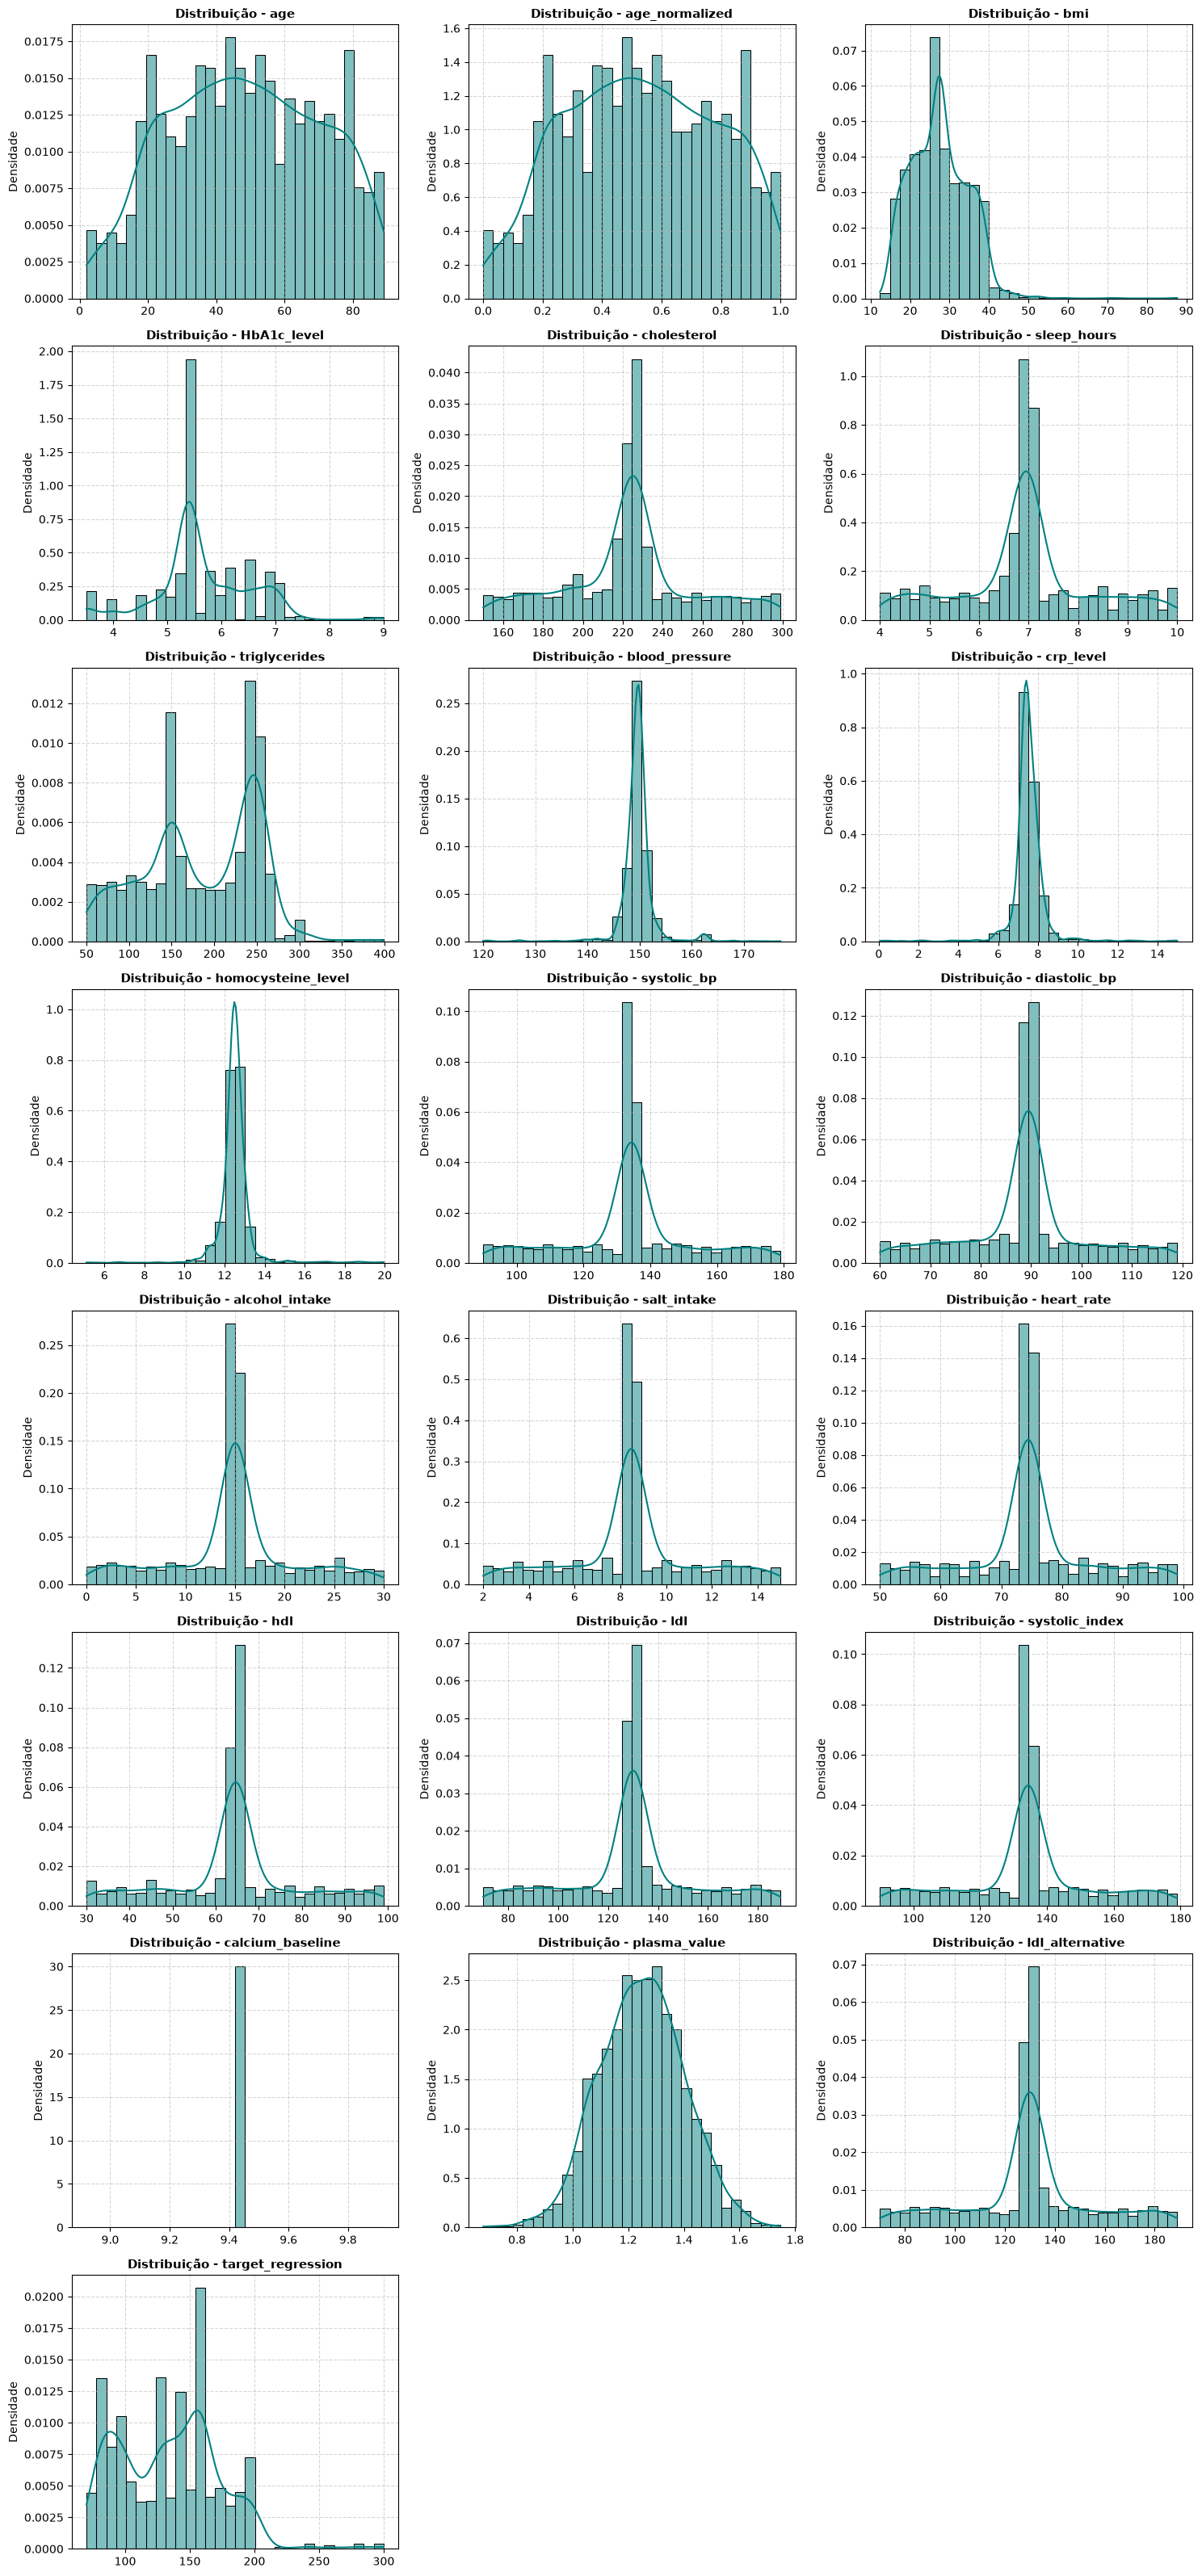

In [16]:
# ============================================================
# 10.2 DISTRIBUTION ANALYSIS - HISTOGRAMS + KDE
# ============================================================

# Configuração da grelha de subplots
n_cols = 3  # Número de colunas
n_vars = len(numeric_cols)
n_rows = math.ceil(n_vars / n_cols)

# Criação da figura
fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 5, n_rows * 4))

# Ajuste do formato do eixos
if n_vars == 1:
    axes = [axes]
else:
    axes = axes.flatten()

# Plot dos histogramas com curva de densidade (KDE)
for i, col in enumerate(numeric_cols):
    sns.histplot(
        df[col],
        kde=True,
        ax=axes[i],
        color="teal",
        bins=30,
        stat="density",  # Permite comparar a curva KDE ajustada
    )
    axes[i].set_title(
        f"Distribuição - {col}", fontsize=11, fontweight="bold"
    )
    axes[i].set_xlabel("")
    axes[i].set_ylabel("Densidade")
    axes[i].grid(True, linestyle="--", alpha=0.5)

# Ocultar eixos não utilizados
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

### 3.2 Outliers (critério do IQR)

In [14]:
# ============================================================
# 10. OUTLIER ANALYSIS - IQR METHOD
# ============================================================

print("\n" + "=" * 60)
print("OUTLIER ANALYSIS")
print("=" * 60)

outlier_summary = []

for col in numeric_cols:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    n_outliers = (
        (df[col] < lower) |
        (df[col] > upper)
    ).sum()

    outlier_summary.append({
        "Variable": col,
        "Outliers": n_outliers,
        "Percentage": n_outliers / len(df) * 100
    })

outlier_summary = (
    pd.DataFrame(outlier_summary)
    .sort_values("Outliers", ascending=False)
)

display(outlier_summary)


OUTLIER ANALYSIS


,Variable,Outliers,Percentage
15,hdl,783,39.15
16,ldl,729,36.45
20,ldl_alternative,729,36.45
12,alcohol_intake,701,35.05
14,heart_rate,691,34.55
10,systolic_bp,683,34.15
17,systolic_index,683,34.15
13,salt_intake,646,32.30
11,diastolic_bp,604,30.20
5,sleep_hours,535,26.75


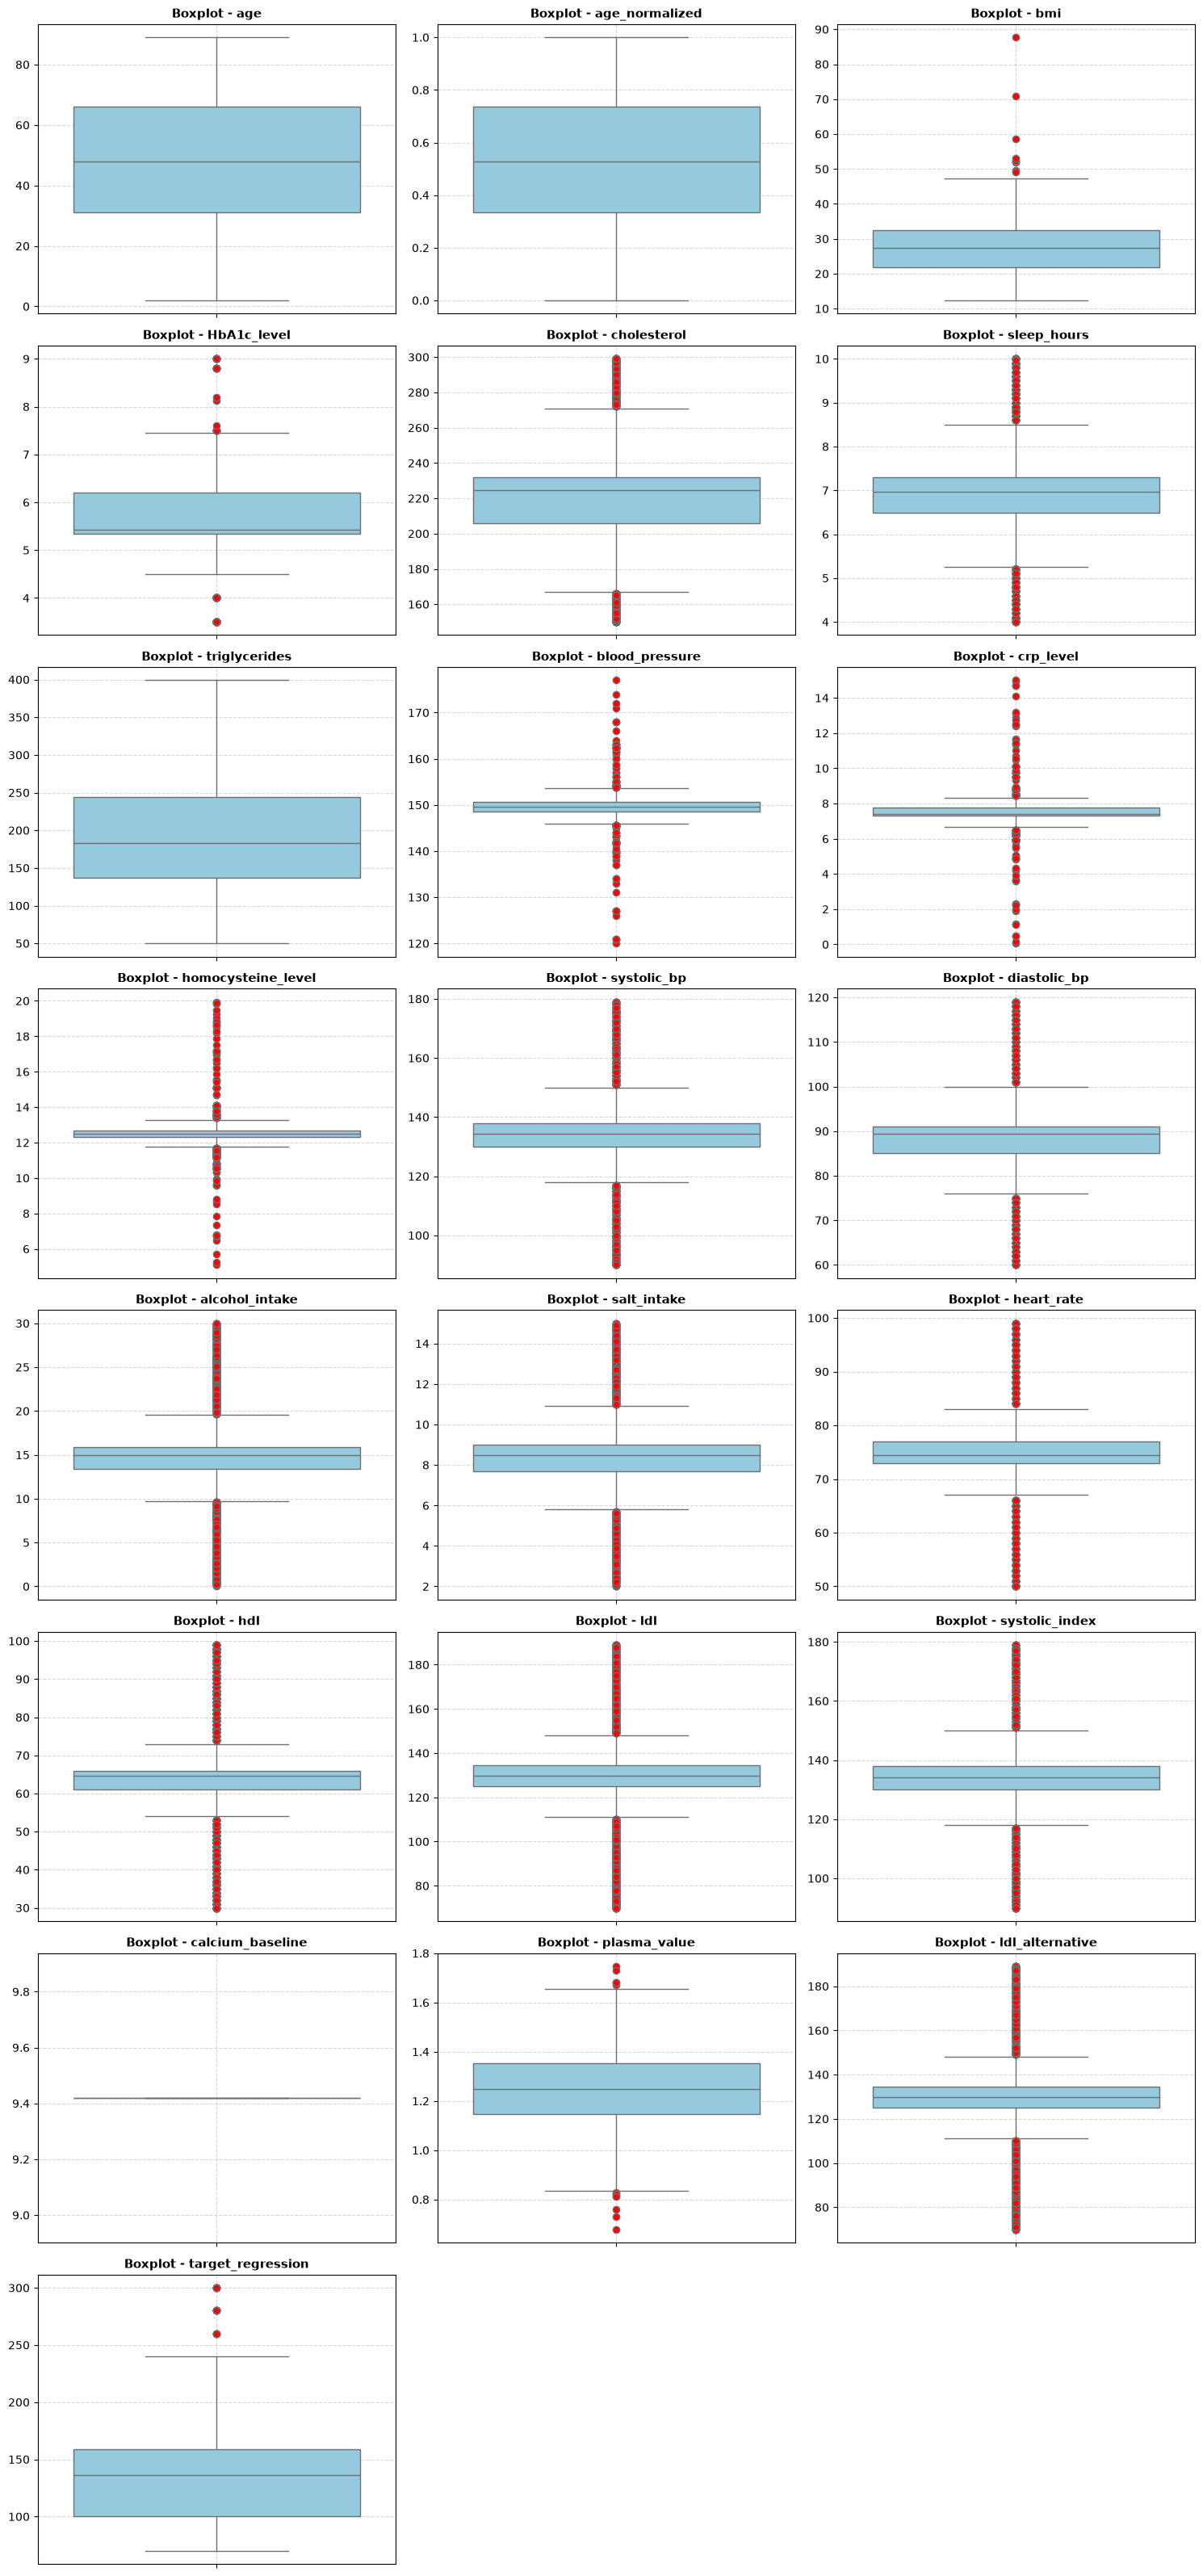

In [15]:
# ============================================================
# 10.1 VISUAL OUTLIER ANALYSIS - BOXPLOTS GRID
# ============================================================

# Configuração da grelha de subplots
n_cols = 3  # Número de colunas no layout
n_vars = len(numeric_cols)
n_rows = math.ceil(n_vars / n_cols)

# Criação da figura
fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 5, n_rows * 4))

# Garantir que 'axes' seja uma lista/array 1D simples
if n_vars == 1:
    axes = [axes]
else:
    axes = axes.flatten()

# Plot de cada variável numérica
for i, col in enumerate(numeric_cols):
    sns.boxplot(
        y=df[col],
        ax=axes[i],
        color="skyblue",
        flierprops=dict(marker="o", markerfacecolor="red", markersize=6),
    )
    axes[i].set_title(f"Boxplot - {col}", fontsize=11, fontweight="bold")
    axes[i].set_ylabel("")
    axes[i].grid(True, linestyle="--", alpha=0.5)

# Ocultar eixos vazios/não utilizados no final da grelha
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

**Leitura:**
- `hdl`, `ldl`, `ldl_alternative`, `alcohol_intake`, `heart_rate`, `systolic_bp`, `systolic_index`, `salt_intake` e `diastolic_bp` têm entre 30% e 39% de valores sinalizados. Nestas variáveis o IQR é muito pequeno face ao desvio-padrão (a maior parte dos valores está colada à mediana), pelo que o critério do IQR sinaliza muitos pontos. Isto indica uma distribuição com pico central e caudas longas e **não** que esses valores sejam erros; por isso não foram removidos. Os diagramas de dispersão da secção 4.2 mostram esse pico como uma faixa vertical no valor mediano, o que sugere (hipótese por confirmar) que valores em falta foram preenchidos com a mediana.
- `target_regression` tem apenas 16 *outliers* (0,8%), todos acima do limite superior (máximo 300).
- `age`, `age_normalized` e `triglycerides` não têm *outliers*.

### 3.3 Distribuição das variáveis categóricas

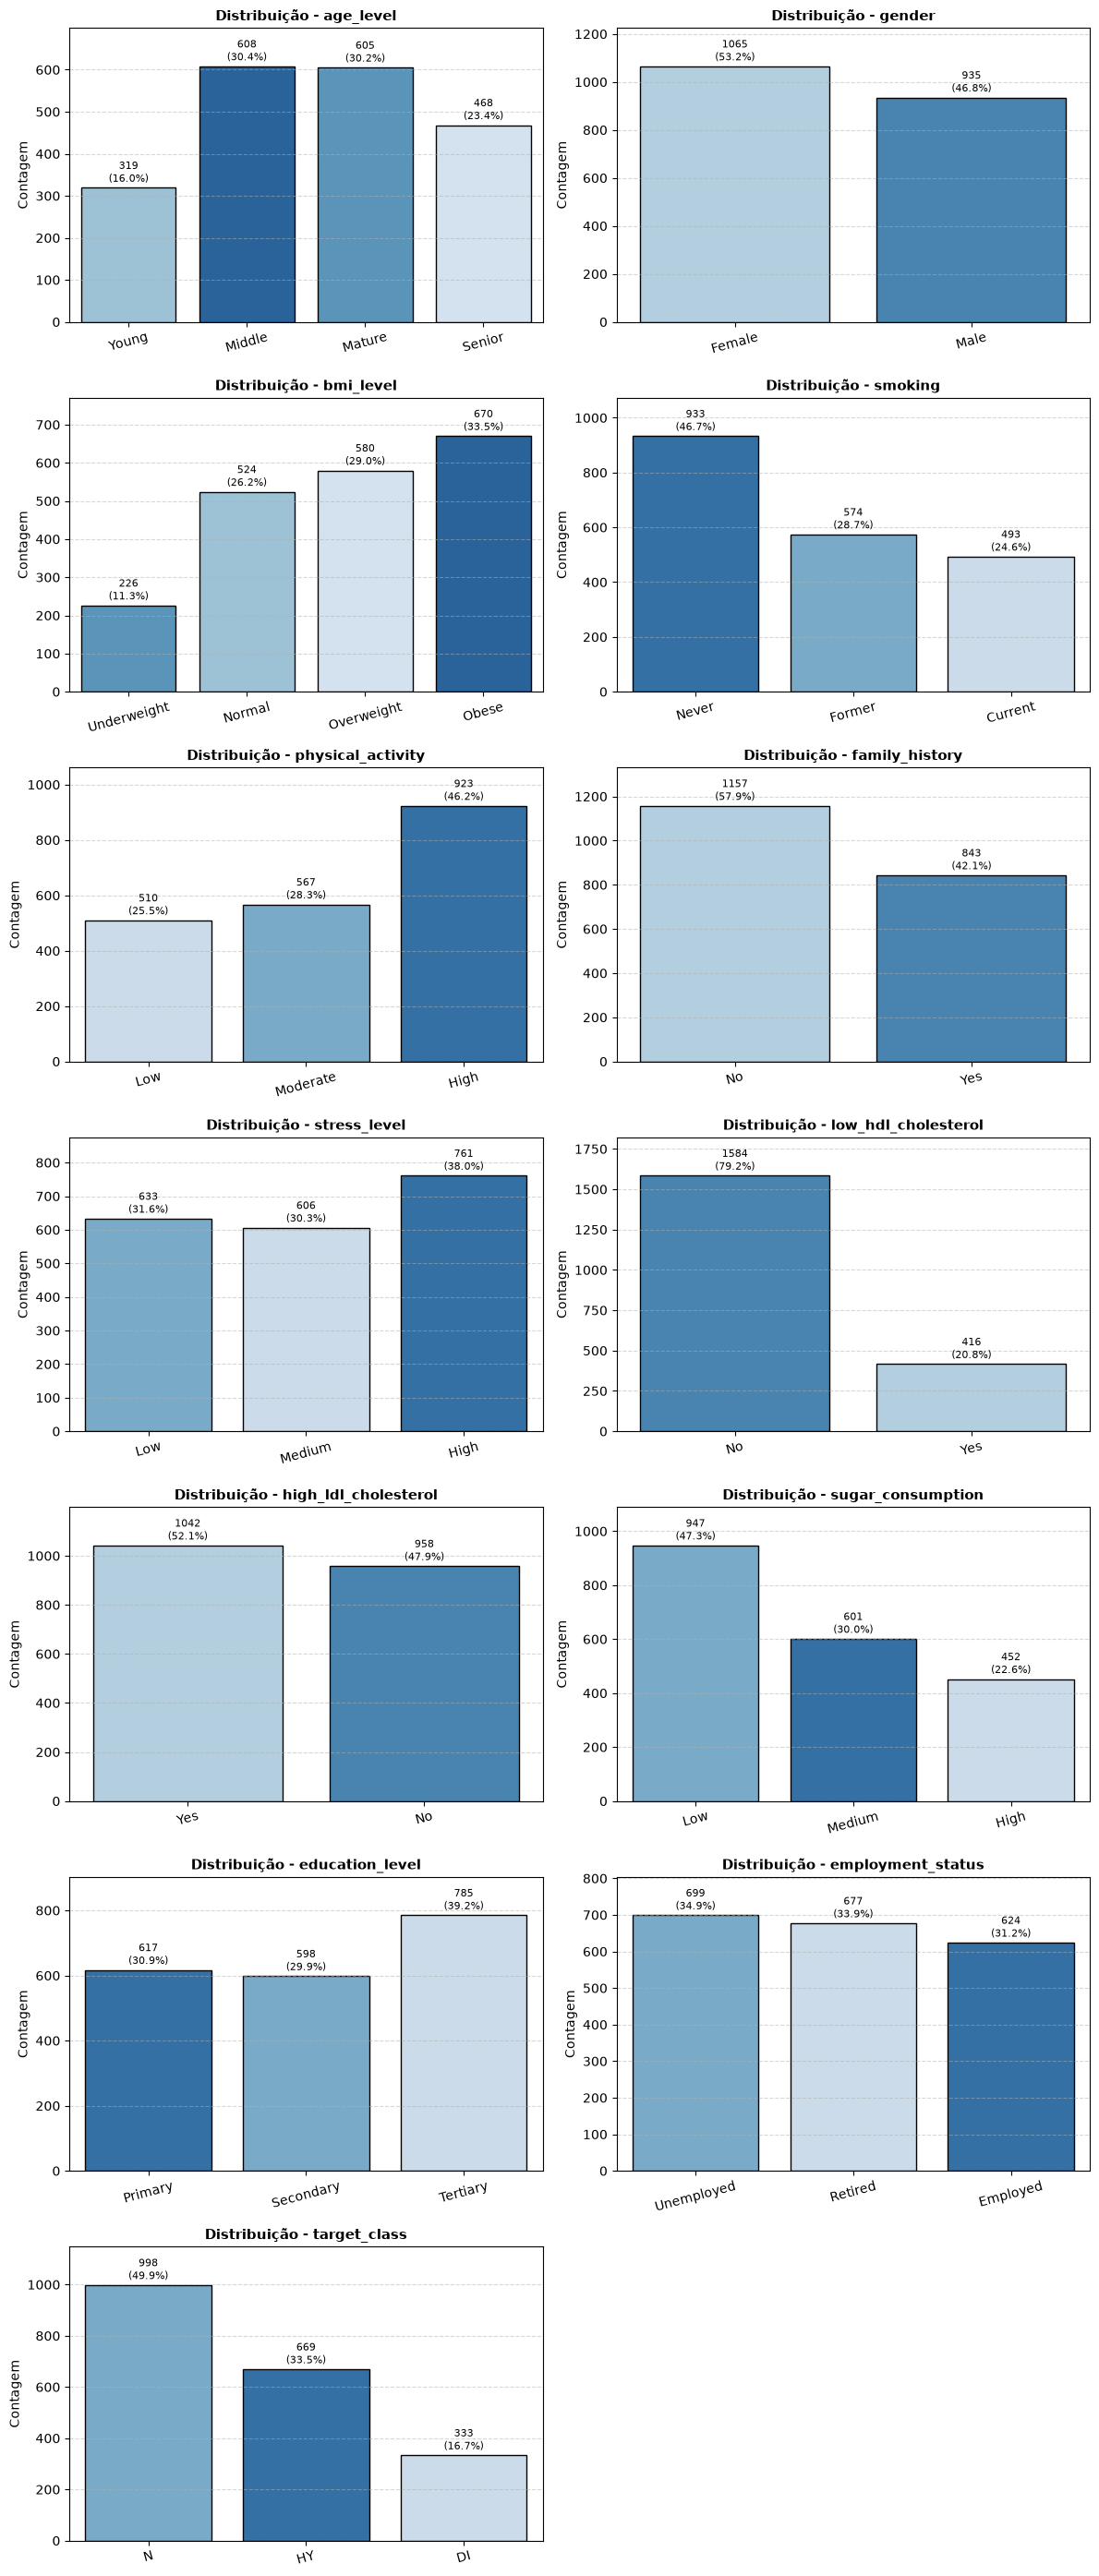

In [17]:
# ============================================================
# 10.3 UNIVARIATE ANALYSIS - CATEGORICAL VARIABLES (BAR CHARTS)
# ============================================================

n_cols = 2
n_vars = len(categorical_cols)
n_rows = math.ceil(n_vars / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 6, n_rows * 4))

if n_vars == 1:
    axes = [axes]
else:
    axes = axes.flatten()

ordinal_orders = {
    "age_level": ["Young", "Middle", "Mature", "Senior"],
    "bmi_level": ["Underweight", "Normal", "Overweight", "Obese"],
    "smoking": ["Never", "Former", "Current"],
    "physical_activity": ["Low", "Moderate", "High"],
    "stress_level": ["Low", "Medium", "High"],
    "sugar_consumption": ["Low", "Medium", "High"],
    "education_level": ["Primary", "Secondary", "Tertiary"],
}

total_obs = len(df)

for i, col in enumerate(categorical_cols):
    if col in ordinal_orders:
        order = [cat for cat in ordinal_orders[col] if cat in df[col].unique()]
    else:
        order = df[col].value_counts().index

    ax = sns.countplot(
        data=df,
        x=col,
        hue=col,
        legend=False,
        order=order,
        ax=axes[i],
        palette="Blues_r",
        edgecolor="black",
    )

    axes[i].set_title(
        f"Distribuição - {col}", fontsize=11, fontweight="bold"
    )
    axes[i].set_xlabel("")
    axes[i].set_ylabel("Contagem")
    axes[i].grid(axis="y", linestyle="--", alpha=0.5)
    axes[i].tick_params(axis="x", rotation=15)
    
    y_max = df[col].value_counts().max()
    axes[i].set_ylim(0, y_max * 1.15)

    for p in ax.patches:
        height = p.get_height()
        if height > 0:
            percentage = (height / total_obs) * 100
            ax.annotate(
                f"{int(height)}\n({percentage:.1f}%)",
                (p.get_x() + p.get_width() / 2.0, height),
                ha="center",
                va="bottom",
                fontsize=8,
                xytext=(0, 2),
                textcoords="offset points",
            )

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

---
## 4. Análise bivariada

Relação entre as features e cada uma das variáveis-alvo, e entre as próprias features:

1. correlação entre features (colinearidade);
2. features vs `target_regression`;
3. `target_regression` vs `target_class`.

### 4.1 Correlação entre features (Pearson)

Mede a relação linear entre pares de preditores. Correlações muito altas entre preditores indicam redundância e causam colinearidade nos modelos lineares.


CORRELATION MATRIX
                         age  age_normalized       bmi  HbA1c_level  \
age                 1.000000        1.000000  0.096402     0.104491   
age_normalized      1.000000        1.000000  0.096402     0.104491   
bmi                 0.096402        0.096402  1.000000     0.041813   
HbA1c_level         0.104491        0.104491  0.041813     1.000000   
cholesterol         0.001560        0.001560  0.002352    -0.006744   
sleep_hours         0.028452        0.028452  0.036743    -0.012072   
triglycerides      -0.236845       -0.236845 -0.003540    -0.061578   
blood_pressure     -0.143100       -0.143101 -0.093575     0.073729   
crp_level           0.037514        0.037514 -0.096554    -0.014108   
homocysteine_level  0.050482        0.050482  0.105355    -0.001573   
systolic_bp         0.016034        0.016034 -0.017043    -0.014468   
diastolic_bp        0.010665        0.010665 -0.014707     0.002383   
alcohol_intake     -0.014907       -0.014907  0.002603   

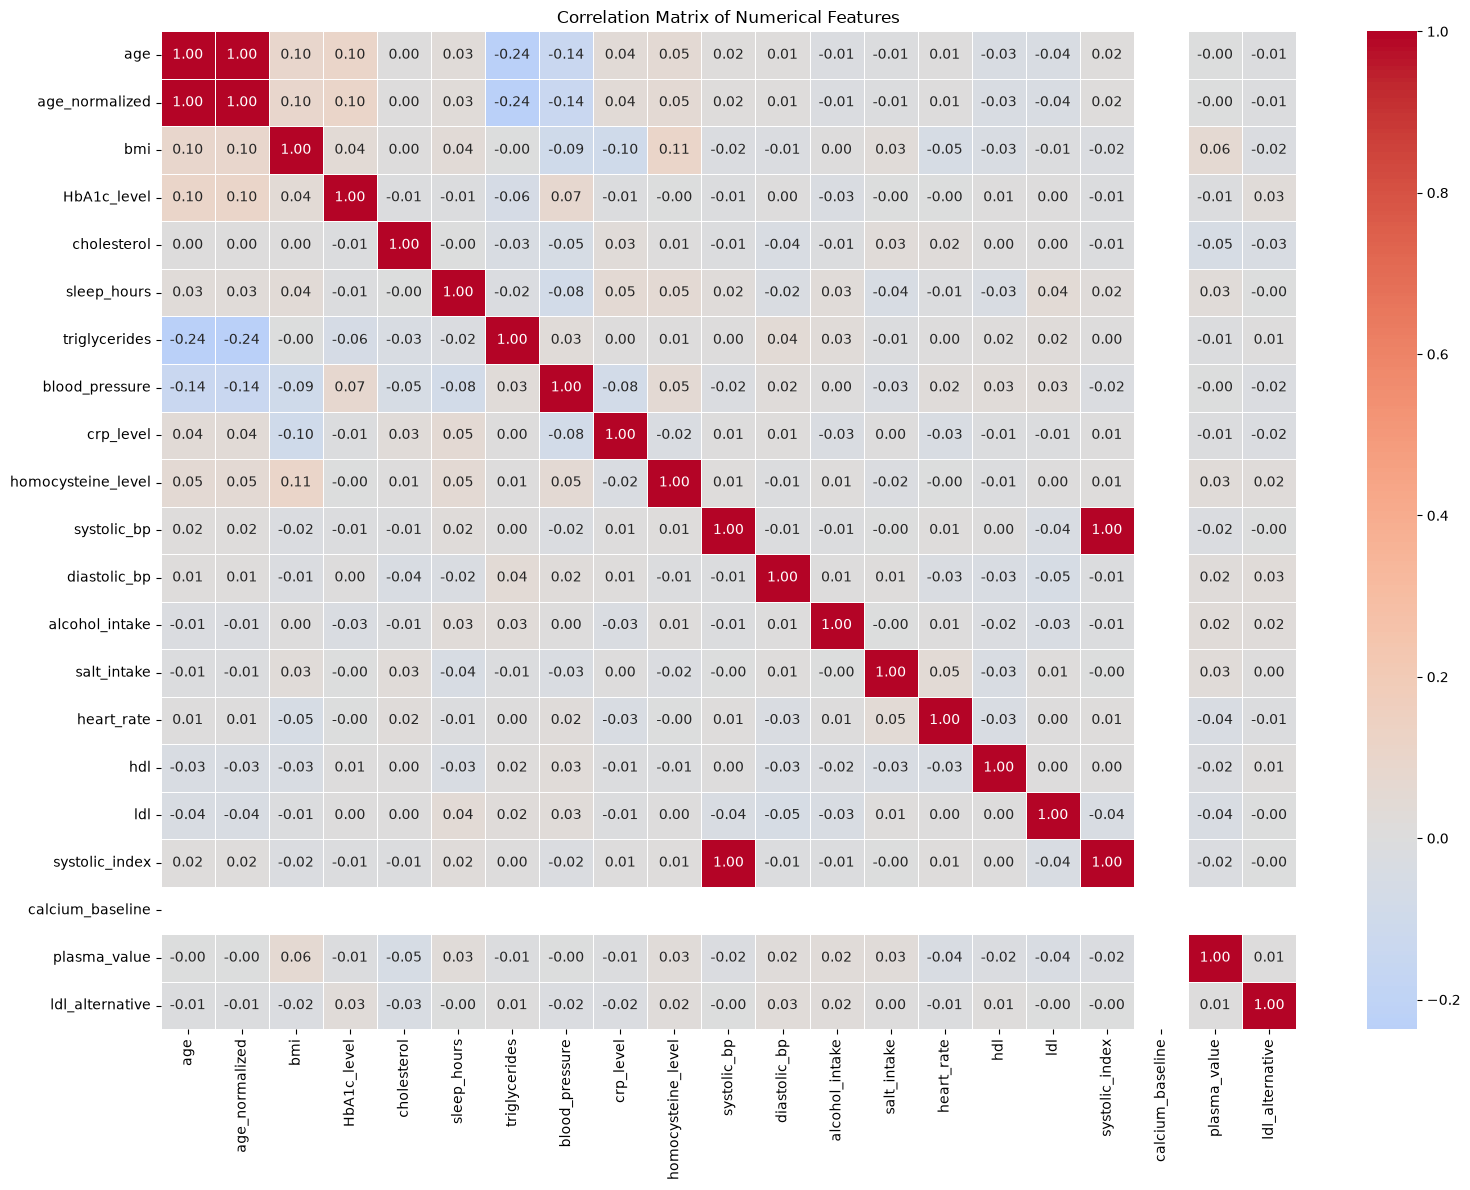

In [18]:
# ============================================================
# 11. CORRELATION MATRIX
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns

print("\n" + "=" * 60)
print("CORRELATION MATRIX")
print("=" * 60)

# Remove target_regression
correlation = df[numeric_cols].drop(columns="target_regression").corr()

print(correlation)

# Heatmap
plt.figure(figsize=(16, 12))

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5
)

plt.title("Correlation Matrix of Numerical Features")
plt.tight_layout()
plt.show()

**Leitura:** fora dos pares `age`/`age_normalized` e `systolic_bp`/`systolic_index` (r = 1), as correlações entre preditores são fracas. A maior em valor absoluto é entre `age` e `triglycerides` (-0,24). A coluna/linha de `calcium_baseline` está vazia (NaN) porque a variável é constante.

### 4.2 Features vs `target_regression`

Correlação de Spearman (monotónica, menos sensível a *outliers* que a de Pearson), diagramas de dispersão para as numéricas e *boxplots* por categoria para as categóricas.

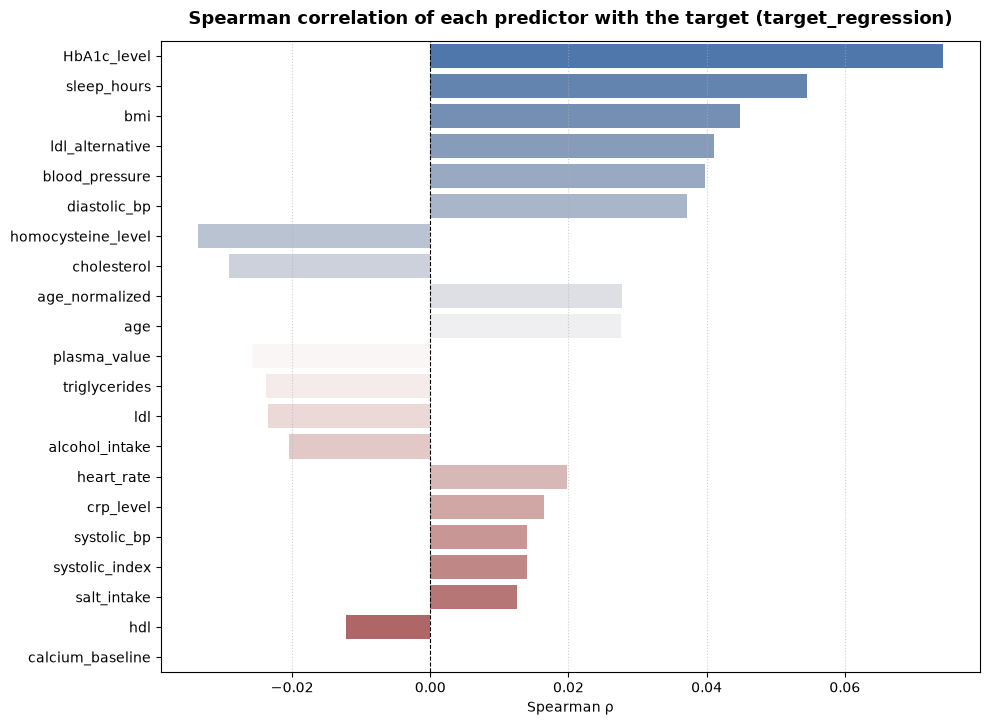

Correlation with the target, sorted by |ρ|:


,Spearman_rho,|rho|
HbA1c_level,0.0742,0.0742
sleep_hours,0.0545,0.0545
bmi,0.0449,0.0449
ldl_alternative,0.0411,0.0411
blood_pressure,0.0398,0.0398
diastolic_bp,0.0371,0.0371
homocysteine_level,-0.0336,0.0336
cholesterol,-0.0291,0.0291
age_normalized,0.0277,0.0277
age,0.0276,0.0276


In [19]:
# Spearman correlation of each candidate predictor with the target (descriptive, full data)
sample_corr = df.sample(min(len(df), 100_000), random_state=42)
numeric_df = sample_corr.select_dtypes(include=["number"])

target_corr = (
    numeric_df.corr(method="spearman")[["target_regression"]]
    .drop("target_regression")
    .rename(columns={"target_regression": "Spearman_rho"})
)
target_corr["|rho|"] = target_corr["Spearman_rho"].abs()
target_corr = target_corr.sort_values(by="|rho|", ascending=False)

plt.figure(figsize=(10, max(6, len(target_corr) * 0.35)))
sns.barplot(x=target_corr["Spearman_rho"], y=target_corr.index, hue=target_corr.index,
            palette="vlag", legend=False)
plt.axvline(0, color="black", linestyle="--", linewidth=0.8)
plt.title("Spearman correlation of each predictor with the target (target_regression)",
          fontsize=13, fontweight="bold", pad=12)
plt.xlabel("Spearman ρ")
plt.ylabel("")
plt.grid(axis="x", linestyle=":", alpha=0.6)
plt.tight_layout()
plt.show()

print("Correlation with the target, sorted by |ρ|:")
display(target_corr.round(4))

C:\Users\moale\AppData\Roaming\Python\Python313\site-packages\numpy\lib\_function_base_impl.py:3036: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
C:\Users\moale\AppData\Roaming\Python\Python313\site-packages\numpy\lib\_function_base_impl.py:3037: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


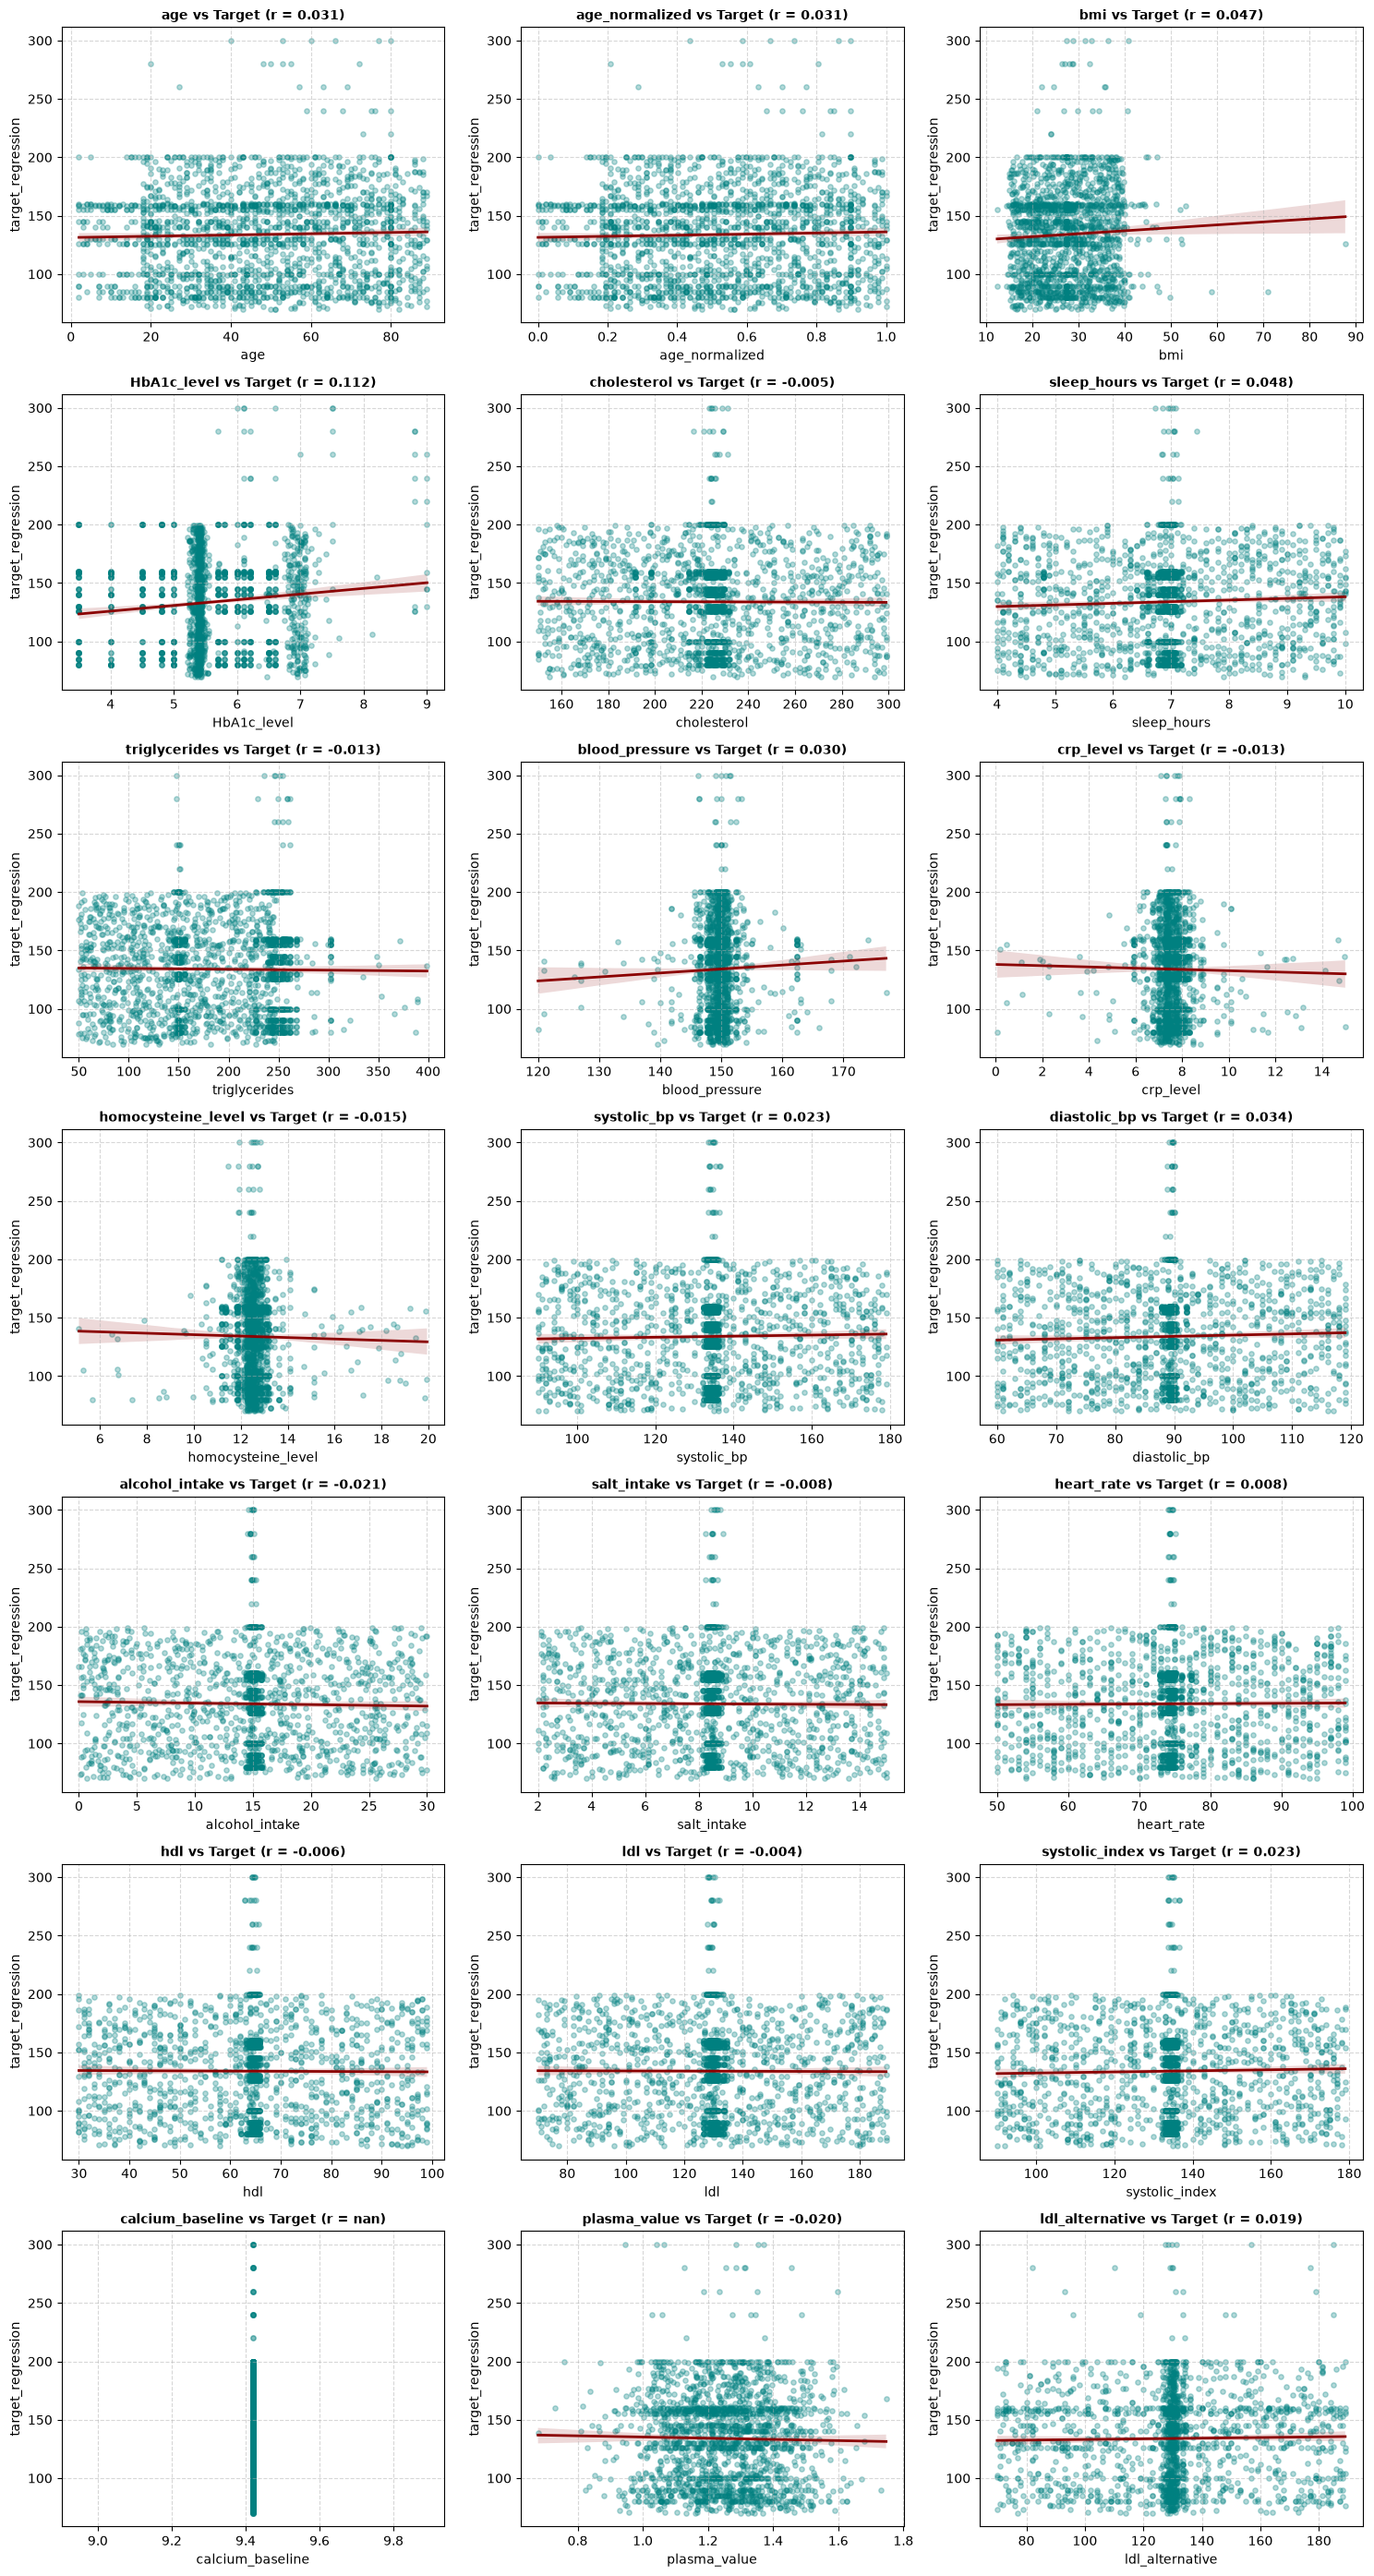

In [20]:
# ============================================================
# SCATTER PLOTS - ALL NUMERICAL FEATURES VS TARGET_REGRESSION
# ============================================================

predictors = [col for col in numeric_cols if col != "target_regression"]

n_cols = 3
n_vars = len(predictors)
n_rows = math.ceil(n_vars / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 5, n_rows * 4))

if n_vars == 1:
    axes = [axes]
else:
    axes = axes.flatten()

for i, col in enumerate(predictors):
    # Calcular correlação de Pearson para exibir no título
    corr_val = df[col].corr(df["target_regression"])

    sns.regplot(
        data=df,
        x=col,
        y="target_regression",
        ax=axes[i],
        scatter_kws={"alpha": 0.3, "color": "teal", "s": 15},
        line_kws={"color": "darkred", "linewidth": 2},
    )

    axes[i].set_title(
        f"{col} vs Target (r = {corr_val:.3f})",
        fontsize=10,
        fontweight="bold",
    )
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("target_regression")
    axes[i].grid(True, linestyle="--", alpha=0.5)

# Ocultar eixos não utilizados
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

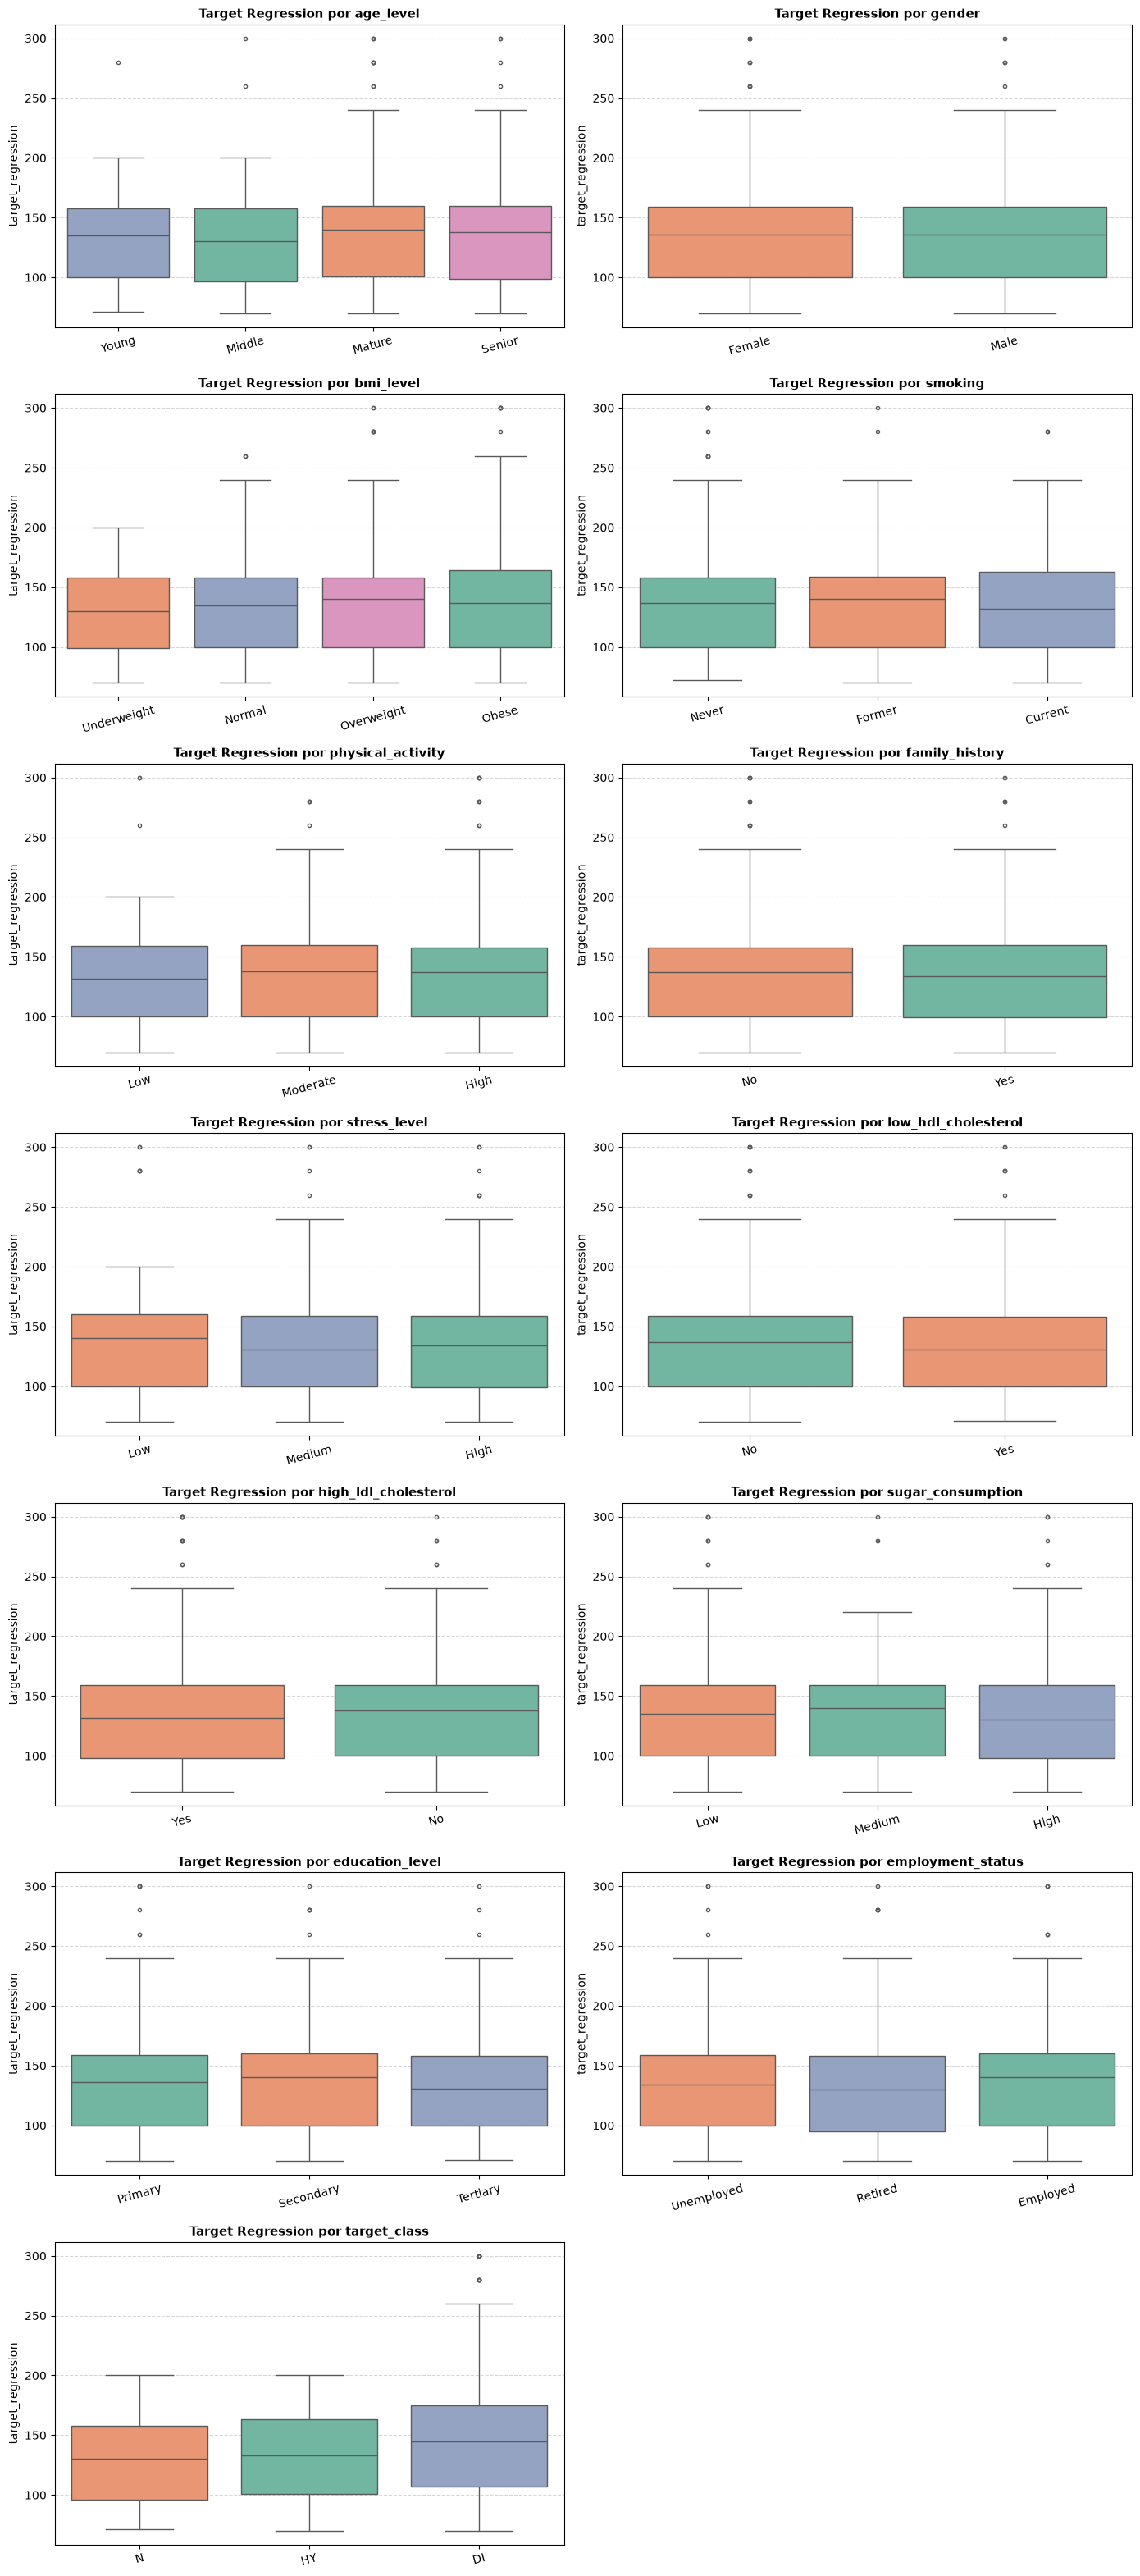

In [21]:
# ============================================================
# CATEGORICAL FEATURES VS TARGET_REGRESSION (BOXPLOTS)
# ============================================================
import math

n_cols = 2
n_vars = len(categorical_cols)
n_rows = math.ceil(n_vars / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 7, n_rows * 4.5))
axes = axes.flatten() if n_vars > 1 else [axes]

# Ordem para ordinais
ordinal_orders = {
    "age_level": ["Young", "Middle", "Mature", "Senior"],
    "bmi_level": ["Underweight", "Normal", "Overweight", "Obese"],
    "smoking": ["Never", "Former", "Current"],
    "physical_activity": ["Low", "Moderate", "High"],
    "stress_level": ["Low", "Medium", "High"],
    "sugar_consumption": ["Low", "Medium", "High"],
    "education_level": ["Primary", "Secondary", "Tertiary"],
}

for i, col in enumerate(categorical_cols):
    order = ordinal_orders.get(col, df[col].value_counts().index.tolist())
    
    sns.boxplot(
        data=df,
        x=col,
        y="target_regression",
        hue=col,
        order=order,
        ax=axes[i],
        palette="Set2",
        fliersize=3
    )
    axes[i].set_title(f"Target Regression por {col}", fontweight="bold", fontsize=11)
    axes[i].set_xlabel("")
    axes[i].set_ylabel("target_regression")
    axes[i].tick_params(axis="x", rotation=15)
    axes[i].grid(axis="y", linestyle="--", alpha=0.5)

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

**Leitura:** todas as correlações de Spearman com `target_regression` são muito fracas (|ρ| < 0,08; a maior é `HbA1c_level`, 0,074). Os diagramas de dispersão não mostram padrões claros (a correlação de Pearson mais alta é 0,11, também com `HbA1c_level`) e as distribuições do alvo são semelhantes entre as categorias. Nota-se ainda que em quase todas as features contínuas existe uma faixa vertical de pontos no valor central (mediana), consistente com a forte concentração referida na secção 3.2. Não se espera, portanto, que a regressão linear explique grande parte da variabilidade do alvo (verificado na parte de regressão).

### 4.3 `target_regression` vs `target_class`

Compara-se a distribuição do alvo de regressão em cada uma das classes.

In [24]:
# ============================================================
# 13. TARGET_REGRESSION BY TARGET_CLASS
# ============================================================

print("\n" + "=" * 60)
print("TARGET_REGRESSION BY TARGET_CLASS")
print("=" * 60)

target_comparison = (
    df.groupby("target_class")["target_regression"]
    .describe()
)

print(target_comparison)


TARGET_REGRESSION BY TARGET_CLASS
              count        mean        std   min     25%    50%    75%    max
target_class                                                                 
DI            333.0  146.603604  49.499412  70.0  107.00  145.0  175.0  300.0
HY            669.0  133.136024  36.781696  70.0  101.00  133.0  163.0  200.0
N             998.0  130.239479  34.926485  71.0   96.25  130.0  158.0  200.0


**Leitura:** a classe `DI` tem média mais alta (146,6) e maior dispersão (desvio-padrão 49,5; máximo 300) do que `HY` (133,1) e `N` (130,2), mas as distribuições sobrepõem-se bastante.

---
## 5. Features constantes, redundantes e não informativas

O enunciado pede para identificar features potencialmente não informativas, constantes ou redundantes e justificar com os resultados. Verificam-se por ordem: constantes, quase constantes e pares fortemente correlacionados (|r| ≥ 0,80).

### 5.1 Variáveis constantes e quase constantes

In [12]:
# ============================================================
# 8. CONSTANT VARIABLES
# ============================================================

print("\n" + "=" * 60)
print("CONSTANT VARIABLES")
print("=" * 60)

constant_cols = [
    col for col in df.columns
    if df[col].nunique() <= 1
]

if constant_cols:
    print(constant_cols)
else:
    print("No constant variables found.")


CONSTANT VARIABLES
['calcium_baseline']


In [13]:
# ============================================================
# 9. NEAR-CONSTANT VARIABLES
# ============================================================

print("\n" + "=" * 60)
print("NEAR-CONSTANT VARIABLES (>95% SAME VALUE)")
print("=" * 60)

near_constant = []

for col in df.columns:
    distribution = df[col].value_counts(normalize=True)

    if distribution.iloc[0] > 0.95:
        near_constant.append({
            "Variable": col,
            "Most Frequent Value": distribution.index[0],
            "Percentage": distribution.iloc[0] * 100
        })

near_constant = pd.DataFrame(near_constant)

if len(near_constant) > 0:
    display(near_constant)
else:
    print("No near-constant variables found.")



NEAR-CONSTANT VARIABLES (>95% SAME VALUE)


,Variable,Most Frequent Value,Percentage
0,calcium_baseline,9.42,100.0


### 5.2 Features fortemente correlacionadas

In [22]:
# ============================================================
# 12. HIGHLY CORRELATED FEATURES
# ============================================================

print("\n" + "=" * 60)
print("HIGHLY CORRELATED FEATURES (|r| >= 0.80)")
print("=" * 60)

corr_pairs = (
    correlation
    .where(
        ~np.eye(
            correlation.shape[0],
            dtype=bool
        )
    )
    .stack()
    .reset_index()
)

corr_pairs.columns = [
    "Feature 1",
    "Feature 2",
    "Correlation"
]

corr_pairs["Abs Correlation"] = (
    abs(corr_pairs["Correlation"])
)

# Remove duplicate pairs
corr_pairs["Pair"] = corr_pairs.apply(
    lambda row: tuple(
        sorted(
            [row["Feature 1"], row["Feature 2"]]
        )
    ),
    axis=1
)

high_corr = (
    corr_pairs[
        corr_pairs["Abs Correlation"] >= 0.80
    ]
    .drop_duplicates("Pair")
    .sort_values(
        "Abs Correlation",
        ascending=False
    )
    .drop(columns="Pair")
)

print(high_corr)


HIGHLY CORRELATED FEATURES (|r| >= 0.80)
       Feature 1       Feature 2  Correlation  Abs Correlation
227  systolic_bp  systolic_index          1.0              1.0
1            age  age_normalized          1.0              1.0


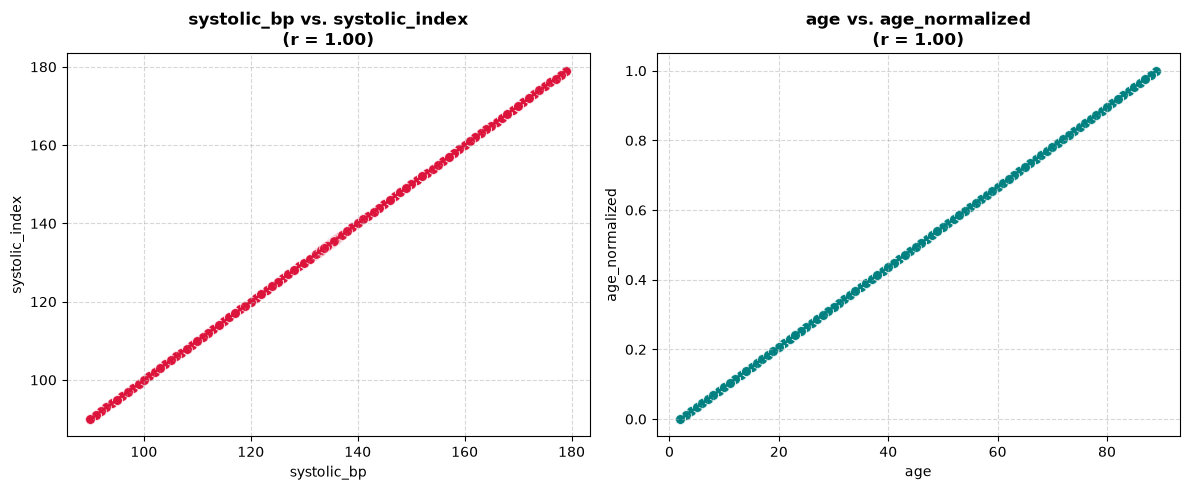

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns

# ============================================================
# VISUALIZAÇÃO DE CORRELAÇÃO PERFEITA (r = 1.0)
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# 1. Gráfico: systolic_bp vs systolic_index
sns.scatterplot(
    data=df,
    x="systolic_bp",
    y="systolic_index",
    ax=axes[0],
    color="crimson",
    s=50,
    alpha=0.8,
)
sns.regplot(
    data=df,
    x="systolic_bp",
    y="systolic_index",
    ax=axes[0],
    color="crimson",
    scatter=False,
    line_kws={"linewidth": 2},
)
axes[0].set_title(
    "systolic_bp vs. systolic_index\n(r = 1.00)", fontsize=12, fontweight="bold"
)
axes[0].grid(True, linestyle="--", alpha=0.5)

# 2. Gráfico: age vs age_normalized
sns.scatterplot(
    data=df,
    x="age",
    y="age_normalized",
    ax=axes[1],
    color="teal",
    s=50,
    alpha=0.8,
)
sns.regplot(
    data=df,
    x="age",
    y="age_normalized",
    ax=axes[1],
    color="teal",
    scatter=False,
    line_kws={"linewidth": 2},
)
axes[1].set_title(
    "age vs. age_normalized\n(r = 1.00)", fontsize=12, fontweight="bold"
)
axes[1].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

**Leitura:**
- `systolic_index` tem exatamente as mesmas estatísticas e r = 1 com `systolic_bp`, ou seja, é um duplicado.
- `age_normalized` tem r = 1 com `age` e varia entre 0 e 1, ou seja, é a idade em escala normalizada.
- `ldl_alternative` tem as mesmas estatísticas descritivas e o mesmo número de valores distintos (242) que `ldl`, mas não aparece entre os pares com |r| ≥ 0,80, pelo que não está linearmente relacionada com `ldl`. Fica sinalizada como suspeita (hipótese por confirmar: cópia de `ldl` com os valores baralhados).
- `age_level` e `bmi_level` são, pela construção e pelos nomes, categorizações de `age` e `bmi`.

### 5.3 Resumo

| Feature(s) | Problema | Evidência | Decisão proposta |
|---|---|---|---|
| `calcium_baseline` | Constante (um único valor, 9,42) | Desvio-padrão 0; 1 valor distinto | Remover (não discrimina nada) |
| `systolic_index` | Duplicado de `systolic_bp` | Valores iguais em 100% das linhas; r = 1 | Remover uma das duas |
| `age_normalized` | Transformação linear de `age` | r = 1; é min-max de `age` | Remover uma das duas |
| `ldl_alternative` | Suspeita de cópia de `ldl` sem relação linear com ela | Mesmas estatísticas e cardinalidade que `ldl`; ausente dos pares com \|r\| ≥ 0,80 | A confirmar; candidata a remover |
| `age_level`, `bmi_level` | Categorizações de `age` e `bmi` | Construção das variáveis | Manter só a versão contínua ou só a categórica |
| `plasma_value`, `heart_rate`, `salt_intake`, `sleep_hours`, `crp_level`, `hdl`, `cholesterol`, ... | Sem relação aparente com os alvos | Correlação de Spearman com `target_regression` inferior a 0,08 em módulo | Candidatas a eliminar na seleção de features (Ridge/Lasso) |

As decisões são **propostas** com base na EDA. Nas fases de modelação a seleção final é feita e avaliada com Ridge e Lasso.

---
## 6. Conclusões

**Qualidade dos dados.** Dataset limpo (sem duplicados nem valores em falta), com 2000 registos e 33 features.

**Alvos.**
- `target_class` está desbalanceado (50% / 33% / 17%, rácio 3:1), pelo que as métricas e as partições devem ter isto em conta.
- `target_regression` é contínua (70 a 300), com assimetria moderada e poucos *outliers*.

**Features a tratar.** Uma variável constante (`calcium_baseline`), duas duplicações exatas ou lineares (`systolic_index`, `age_normalized`), uma variável suspeita de ser cópia de `ldl` (`ldl_alternative`) e duas categorizações de variáveis contínuas (`age_level`, `bmi_level`).

**Relação com `target_class`.** O alvo de regressão tem média mais alta na classe `DI` (146,6) do que em `HY` e `N`, mas com bastante sobreposição.

**Relação com `target_regression`.** Todas as correlações com o alvo são muito fracas (|ρ| < 0,08), por isso o ajuste de modelos lineares a este alvo deverá ter capacidade explicativa limitada.

**Outliers.** Muitas variáveis têm uma percentagem elevada de pontos fora do critério do IQR, devido à forte concentração em torno da mediana. Não foram removidos.

---
## Apêndice. Codificação das variáveis categóricas

Preparação do dataset para os modelos das partes seguintes (cópia em `df_encoded`, o `df` original não é alterado):

- **ordinal** (mantém a ordem natural): `bmi_level`, `physical_activity`, `stress_level`, `sugar_consumption`;
- **binária** (0/1): `gender`, `family_history`, `low_hdl_cholesterol`, `high_ldl_cholesterol`;
- ***one-hot***: `age_level`, `smoking`, `education_level`, `employment_status` (sem ordem natural, ou já representadas por `age`).

Verifica-se no final que a codificação não introduziu valores nulos.

In [29]:
# Create a copy to preserve the original dataframe
df_encoded = df.copy()

# Identificar as colunas alvo
target_columns = ["target_class", "target_regression"]

# 1. Ordinal encoding
ordinal_mappings = {
    "bmi_level": {
        "Underweight": 1,
        "Normal": 2,
        "Overweight": 3,
        "Obese": 4
    },
    "physical_activity": {
        "Low": 1,
        "Moderate": 2,
        "High": 3
    },
    "stress_level": {
        "Low": 1,
        "Medium": 2,
        "High": 3
    },
    "sugar_consumption": {
        "Low": 1,
        "Medium": 2,
        "High": 3
    }
}

for column, mapping in ordinal_mappings.items():
    df_encoded[column] = df_encoded[column].map(mapping)


# 2. Binary encoding
binary_mappings = {
    "gender": {
        "Male": 0,
        "Female": 1
    },
    "family_history": {
        "No": 0,
        "Yes": 1
    },
    "low_hdl_cholesterol": {
        "No": 0,
        "Yes": 1
    },
    "high_ldl_cholesterol": {
        "No": 0,
        "Yes": 1
    }
}

for column, mapping in binary_mappings.items():
    df_encoded[column] = df_encoded[column].map(mapping)


# 3. One-hot encoding
one_hot_categories = {
    "age_level": ["Young", "Middle", "Mature", "Senior"],
    "smoking": ["Never", "Former", "Current"],
    "education_level": ["Primary", "Secondary", "Tertiary"],
    "employment_status": ["Unemployed", "Employed", "Retired"]
}

for column, categories in one_hot_categories.items():
    df_encoded[column] = pd.Categorical(
        df_encoded[column],
        categories=categories
    )

df_encoded = pd.get_dummies(
    df_encoded,
    columns=list(one_hot_categories.keys()),
    dtype=int
)

# Check the result
display(df_encoded.head(10))
print("Encoded dataset shape:", df_encoded.shape)
display(df_encoded.dtypes.to_frame("Data type"))

# 6. Verificar o resultado
print("Original shape:", df.shape)
print("Encoded shape:", df_encoded.shape)

print("\nColunas finais:")
print(df_encoded.columns.tolist())

# Identificar as colunas que foram codificadas
encoded_columns = (
    list(ordinal_mappings.keys())
    + list(binary_mappings.keys())
    + [
        col
        for col in df_encoded.columns
        if any(
            col.startswith(f"{category}_")
            for category in one_hot_categories
        )
    ]
)

# Manter apenas colunas que existem no DataFrame
encoded_columns = [
    col for col in encoded_columns
    if col in df_encoded.columns
]


print("\nValores nulos nas colunas codificadas:")
print(df_encoded[encoded_columns].isna().sum())

,gender,bmi_level,age,age_normalized,bmi,HbA1c_level,cholesterol,sleep_hours,triglycerides,physical_activity,...,age_level_Senior,smoking_Never,smoking_Former,smoking_Current,education_level_Primary,education_level_Secondary,education_level_Tertiary,employment_status_Unemployed,employment_status_Employed,employment_status_Retired
0,0,4,44,0.482758,35.70,5.398540,250.000000,5.300000,235.000000,3,...,0,1,0,0,1,0,0,0,1,0
1,0,4,49,0.540230,34.97,6.500000,224.684501,7.060728,149.460563,2,...,0,0,1,0,0,1,0,1,0,0
2,0,1,4,0.022989,17.64,6.000000,228.130653,7.080402,156.115578,2,...,0,1,0,0,0,0,1,0,1,0
3,0,1,40,0.436781,17.30,5.421429,299.000000,9.500000,150.000000,1,...,0,0,0,1,1,0,0,0,1,0
4,1,2,27,0.287356,24.80,5.374373,277.000000,8.500000,187.000000,3,...,0,0,0,1,0,0,1,0,1,0
5,0,2,44,0.482758,20.60,5.332298,280.000000,5.000000,57.000000,3,...,0,0,0,1,0,1,0,0,0,1
6,1,4,85,0.954022,38.80,5.311429,247.000000,7.200000,212.000000,3,...,1,0,0,1,1,0,0,1,0,0
7,1,4,49,0.540229,33.70,6.950128,264.000000,7.300000,158.000000,1,...,0,0,1,0,0,0,1,1,0,0
8,1,1,29,0.310344,18.40,5.472727,184.000000,9.800000,115.000000,2,...,0,1,0,0,1,0,0,1,0,0
9,0,4,65,0.724137,38.10,5.436598,262.000000,10.000000,223.000000,1,...,0,0,0,1,0,1,0,1,0,0


Encoded dataset shape: (2000, 44)


,Data type
gender,int64
bmi_level,int64
age,int64
age_normalized,float64
bmi,float64
HbA1c_level,float64
cholesterol,float64
sleep_hours,float64
triglycerides,float64
physical_activity,int64


Original shape: (2000, 35)
Encoded shape: (2000, 44)

Colunas finais:
['gender', 'bmi_level', 'age', 'age_normalized', 'bmi', 'HbA1c_level', 'cholesterol', 'sleep_hours', 'triglycerides', 'physical_activity', 'family_history', 'stress_level', 'low_hdl_cholesterol', 'high_ldl_cholesterol', 'blood_pressure', 'sugar_consumption', 'crp_level', 'homocysteine_level', 'systolic_bp', 'diastolic_bp', 'alcohol_intake', 'salt_intake', 'heart_rate', 'hdl', 'ldl', 'systolic_index', 'calcium_baseline', 'plasma_value', 'ldl_alternative', 'target_regression', 'target_class', 'age_level_Young', 'age_level_Middle', 'age_level_Mature', 'age_level_Senior', 'smoking_Never', 'smoking_Former', 'smoking_Current', 'education_level_Primary', 'education_level_Secondary', 'education_level_Tertiary', 'employment_status_Unemployed', 'employment_status_Employed', 'employment_status_Retired']

Valores nulos nas colunas codificadas:
bmi_level                       0
physical_activity               0
stress_level      